# Estudo Comparativo de Classificação Acústica Submarina — Dataset IARA
### Notebook 34: CNN LOFAR do Artigo — Reprodução e Erros em SMALL e MEDIUM

**Autor:** Evandro Rocha (UFRJ / COPPE / PEE)
**Data:** Outubro de 2026

---

A CNN LOFAR é o melhor modelo da Tabela 7 do artigo do IARA (Silva et al., 2025). Até aqui o repositório não a tinha: a "CNN LOFAR" usada antes colapsava (SP 35,4). Ela foi implementada em `test_scripts/cnn_lofar.py` com a configuração do grid search do artigo (`training_scripts/grid_search.py`): conv 512/128, ReLU, max pooling 4×2, dropout 0,4, BatchNorm, kernel 5, camada densa de 128, saída Sigmoid, Adam (lr 1e-6, weight decay 1e-3), batch 32, paciência 32, imagens de 32 janelas LOFAR com 50% de sobreposição. Treinada nos 10 folds do 5×2cv oficial (~4–7 h por fold numa RTX 5060 Ti).

Também foi corrigida a avaliação das CNNs no pipeline (`src/iara/ml/models/trainer.py`): desde o commit f04bb3b ela passava janelas soltas ao modelo em vez de imagens.

**Perguntas:** (1) reproduzimos a Tabela 7? (2) como ela se compara aos outros modelos? (3–5) como são os erros em SMALL e MEDIUM? (6) ela estava insegura quando errou? (7) erra as mesmas gravações que os outros modelos?

**Resumo:**
- **Reprodução:** SP 66,49 ± 1,28 (artigo 66,05 ± 1,90), ACC 67,29 ± 1,19 (artigo 67,02), F1 66,64 ± 1,37 (artigo 66,29). Diferenças de 0,27 a 0,44 ponto, dentro do desvio do artigo.
- **SMALL é a pior classe também aqui:** recall 47,8%; os erros vão para MEDIUM (44%), LARGE (43%) e BACKGROUND (13%).
- **MEDIUM:** recall 63,9%; 62% dos erros vão para SMALL.
- **Contra os outros modelos:** a CNN LOFAR não difere dos dois modelos mais próximos dos do artigo, os MLPs (MLP LOFAR p = 0,723, MLP MEL p = 0,637), como no artigo.
- **Navio no treino:** o acerto sobe +10,9 pontos no SMALL e +25,5 no MEDIUM quando o navio da gravação de teste tem gravações no treino.
- **Confiança:** a CNN erra o SMALL tão segura quanto acerta (AUC da margem 0,54); no MEDIUM a confiança separa parcialmente (0,70).
- **Núcleo do NB32:** das 26 gravações SMALL que ≥ 15 de 16 modelos erram, a CNN acerta em média 1,0%; ela não resolve o núcleo.

Predição por gravação = voto majoritário das janelas (como no artigo); todas as tabelas são calculadas na execução.

In [1]:
import os, sys, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, mannwhitneyu
from sklearn.metrics import roc_auc_score
try:
    from IPython.display import display
except ImportError:
    display = print

for _p in ('.', 'src', 'notebooks', 'notebooks/src'):
    if os.path.exists(os.path.join(_p, 'iara_results.py')) and os.path.abspath(_p) not in sys.path:
        sys.path.insert(0, os.path.abspath(_p))
import iara_results as R

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({'font.family': 'sans-serif', 'font.size': 10, 'figure.dpi': 120})
pd.set_option('display.precision', 2); pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
CLS = dict(enumerate(R.CLASSES))
SMALL, MEDIUM, LARGE, BG = 0, 1, 2, 3
CNN = 'cnn_lofar'

# Tabela 7 do artigo (IARA UO, por gravação)
ARTIGO = {'CNN LOFAR': {'SP': (66.05, 1.90), 'ACC': (67.02, 1.78), 'F1': (66.29, 2.13)},
          'CNN MEL': {'SP': (63.52, 2.26), 'ACC': (64.99, 2.09), 'F1': (63.04, 2.02)},
          'MLP LOFAR': {'SP': (66.51, 1.39)}, 'MLP MEL': {'SP': (63.38, 1.81)},
          'RF LOFAR': {'SP': (56.92, 1.69)}, 'RF MEL': {'SP': (62.22, 1.86)}}
# Tabela 8 do artigo: p do F-test 5x2cv (SP) da CNN LOFAR contra cada modelo
ARTIGO_P = {'RF MEL': 0.12, 'MLP MEL': 0.20, 'CNN MEL': 0.36, 'RF LOFAR': 0.00, 'MLP LOFAR': 0.76}

# Modelos do repositório (não necessariamente idênticos aos do artigo; ver a coluna 'igual ao artigo?')
OUTROS = {
    'MLP LOFAR': ('mlp_lofar', 'próximo: arquitetura do artigo, mas com dropout 0,2 (artigo: sem dropout) e paciência 16 (grid: 8)'),
    'MLP MEL': ('mlp', 'próximo: arquitetura do artigo, paciência 16 (grid: 8)'),
    'RF LOFAR': ('rf_lofar5s_n100_balanced_4c', 'não: janelas de 5 s, 100 árvores, balanceado'),
    'RF MEL': ('rf_mel5s_n100_balanced_4c', 'não: janelas de 5 s, 100 árvores, balanceado'),
    'CNN MEL': ('cnn', 'não: test_scripts/cnn.py (128/64, lr 1e-5, sem sobreposição)'),
    'SVM MEL': ('svm_nystroem_4000_log_melgram_elasticnet_l1r0.15_C2.0', 'não está no artigo'),
    'SVM LOFAR': ('svm_nystroem_6000_lofar_elasticnet_l1r0.15', 'não está no artigo'),
    'BiGRU MEL': ('bigru_att_mel5s_h64_s15-5_e20_4c', 'não está no artigo'),
    'BiGRU LOFAR': ('bigru_att_lofar5s_h128_s15-5_e15_4c', 'não está no artigo'),
}

meta = pd.read_csv(os.path.join(R.ROOT, 'src', 'iara', 'dataset_info', 'iara.csv'), dtype={'Ship ID': str, 'ID': str})
meta['Ship ID'] = meta['Ship ID'].str.strip()
for c in ('Length', 'CPA time', 'Wind', 'Sea state', 'Rain'):
    meta[c] = pd.to_numeric(meta[c], errors='coerce')
meta['Arquivo'] = meta.Dataset + '-' + meta.ID + '.wav'
meta = meta.set_index(meta.ID.astype(int))

# Predições por gravação (voto das janelas) e probabilidades médias por gravação
FP = R.file_predictions(CNN)
rows = []
for k in range(10):
    w = pd.read_csv(os.path.join(R.exp_dir(CNN), 'eval', f'fold_{k}', f'{CNN}_multiclass_test.csv'))
    P = w[[f'Prediction_{c}' for c in range(4)]].clip(lower=0).values
    P = P / np.maximum(P.sum(1, keepdims=True), 1e-12)
    pm = pd.DataFrame(P, columns=['p0', 'p1', 'p2', 'p3']).assign(File=w.File.values).groupby('File').mean()
    sp = pd.read_csv(os.path.join(R.exp_dir(OUTROS['RF LOFAR'][0]), 'eval', f'fold_{k}', f"{OUTROS['RF LOFAR'][0]}_split.csv"))
    trn = meta.loc[sp[sp.Subset == 'trn'].File.astype(int), 'Ship ID'].value_counts()
    d = FP[k].join(pm, on='File')
    d['fold'] = k
    d['navio no treino'] = [trn.get(s, 0) > 0 for s in meta.loc[d.File, 'Ship ID']]
    rows.append(d)
D = pd.concat(rows, ignore_index=True)
D['acertou'] = D.Prediction == D.Target
Pm = D[['p0', 'p1', 'p2', 'p3']].values
D['margem'] = np.sort(Pm, 1)[:, -1] - np.sort(Pm, 1)[:, -2]
D['Classe'] = D.Target.map(CLS); D['Predita'] = D.Prediction.map(CLS)

# Uma linha por gravação: taxa de erro da CNN nos ~5 folds em que a gravação é teste
G = D.groupby('File').agg(Target=('Target', 'first'), erro_cnn=('acertou', lambda s: 1 - s.mean()), vezes=('fold', 'size'),
                          **{f'→ {CLS[c]}': ('Prediction', lambda s, c=c: (s == c).mean()) for c in range(4)})
G['Classe'] = G.Target.map(CLS)
G['CNN'] = np.select([G.erro_cnn == 0, G.erro_cnn == 1], ['sempre acerta', 'sempre erra'], 'às vezes')
G = G.join(meta[['Arquivo', 'Dataset', 'Ship ID', 'Name', 'DETAILED TYPE', 'Length', 'CPA time']], on='File')

# Grupos do Notebook 32 (16 modelos: RF, SVM, MLP, BiGRU × MEL, LOFAR, HHT, DEMON)
FAM16 = {
    'RF': ['rf_mel5s_n100_balanced_4c', 'rf_lofar5s_n100_balanced_4c', 'rf_hht_n100_balanced_4c', 'rf_demon_n100_balanced_4c'],
    'SVM': ['svm_nystroem_4000_log_melgram_elasticnet_l1r0.15_C2.0', 'svm_nystroem_6000_lofar_elasticnet_l1r0.15',
            'svm_nystroem_6000_hht_C2.0_elasticnet_l1r0.15_4c', 'svm_nystroem_6000_demon_C2.0_elasticnet_l1r0.15_it1000_4c'],
    'MLP': ['mlp', 'mlp_lofar', 'mlp_hht_h32-16_e30_4c', 'mlp_demon_h32-16_e30_4c'],
    'BiGRU': ['bigru_att_mel5s_h64_s15-5_e20_4c', 'bigru_att_lofar5s_h128_s15-5_e15_4c', 'bigru_att_hht_h64_s15-5_e20_4c',
              'bigru_att_demon_h64_s15-5_e20_4c'],
}
M16 = sum(FAM16.values(), [])
nerr = []
for k, d in R.aligned(M16).items():
    nerr.append(pd.DataFrame({'File': d.File.values,
                              'n_err16': (np.column_stack([d[e].values for e in M16]) != d.Target.values[:, None]).sum(1)}))
N16 = pd.concat(nerr).groupby('File').n_err16.mean()
G['erram (de 16)'] = N16
G['grupo NB32'] = np.select([G['erram (de 16)'] >= 15, G['erram (de 16)'] <= 4], ['núcleo', 'fácil'], 'meio')

FEAT_CSV = os.path.join(R.ROOT, 'reports', 'small', 'features_acusticas.csv')
FEAT = pd.read_csv(FEAT_CSV).set_index('File') if os.path.exists(FEAT_CSV) else None
if FEAT is not None:
    G = G.join(FEAT, on='File')
print(f'{len(G)} gravações; {len(D)} predições (gravação × fold); medidas acústicas: {FEAT is not None}')

1706 gravações; 6390 predições (gravação × fold); medidas acústicas: True


## 1. Reprodução da Tabela 7 e comparação com os outros modelos

O F-test 5×2cv (Alpaydin, 1999) compara o SP fold a fold, como na Tabela 8 do artigo. A coluna **igual ao artigo?** indica o quanto o modelo do repositório se aproxima do artigo; nenhum é idêntico, e quanto mais diferente, menos o p é comparável ao da Tabela 8.

In [2]:
FM = R.fold_metrics(CNN)
display(FM[['SP', 'ACC', 'F1'] + [f'R_{c}' for c in R.CLASSES]].round(2))
S = R.summary(CNN)
REPRO = pd.DataFrame({m: {'nosso (10 folds)': f'{S[m][0]:.2f} ± {S[m][1]:.2f}',
                          'artigo (Tabela 7)': f'{ARTIGO["CNN LOFAR"][m][0]:.2f} ± {ARTIGO["CNN LOFAR"][m][1]:.2f}',
                          'Δ': round(S[m][0] - ARTIGO['CNN LOFAR'][m][0], 2),
                          'Δ / desvio do artigo': round((S[m][0] - ARTIGO['CNN LOFAR'][m][0]) / ARTIGO['CNN LOFAR'][m][1], 2)}
                      for m in ('SP', 'ACC', 'F1')}).T
display(REPRO)

rows = []
for nome, (exp, igual) in OUTROS.items():
    s = R.summary(exp)['SP']; F_, p_ = R.f_test_5x2(CNN, exp)
    rows.append({'modelo': nome, 'igual ao artigo?': igual, 'SP (nosso)': f'{s[0]:.2f} ± {s[1]:.2f}',
                 'SP (artigo)': (f"{ARTIGO[nome]['SP'][0]:.2f} ± {ARTIGO[nome]['SP'][1]:.2f}" if nome in ARTIGO else '—'),
                 'Δ CNN LOFAR − modelo': S['SP'][0] - s[0], 'F': F_, 'p (nosso)': p_, 'SP nosso (média)': s[0],
                 'p (artigo, Tab. 8)': ARTIGO_P.get(nome, np.nan)})
FT = pd.DataFrame(rows).set_index('modelo')
print('CNN LOFAR × outros modelos (F-test 5×2cv sobre o SP):'); display(FT.round(3))

,SP,ACC,F1,R_SMALL,R_MEDIUM,R_LARGE,R_BACKGROUND
fold,,,,,,,
0,68.49,69.03,68.98,50.56,70.47,72.43,82.65
1,65.77,66.95,65.38,41.57,65.10,73.36,87.76
2,67.47,68.46,67.76,44.38,71.14,70.56,87.76
3,65.99,66.62,65.74,53.93,55.70,70.09,86.73
4,66.68,67.06,66.62,54.49,62.42,68.69,82.65
5,63.88,65.05,64.74,39.89,62.42,75.23,82.65
6,66.91,67.77,68.16,47.19,61.07,77.10,85.71
7,65.57,66.25,64.89,48.88,64.43,64.95,86.73
8,68.07,68.89,67.49,47.19,69.13,71.50,87.76


,nosso (10 folds),artigo (Tabela 7),Δ,Δ / desvio do artigo
SP,66.49 ± 1.28,66.05 ± 1.90,0.44,0.23
ACC,67.29 ± 1.19,67.02 ± 1.78,0.27,0.15
F1,66.64 ± 1.37,66.29 ± 2.13,0.35,0.16


CNN LOFAR × outros modelos (F-test 5×2cv sobre o SP):


,igual ao artigo?,SP (nosso),SP (artigo),Δ CNN LOFAR − modelo,F,p (nosso),SP nosso (média),"p (artigo, Tab. 8)"
modelo,,,,,,,,
MLP LOFAR,"próximo: arquitetura do artigo, mas com dropou...",66.24 ± 1.78,66.51 ± 1.39,0.24,0.67,7.23e-01,66.24,0.76
MLP MEL,"próximo: arquitetura do artigo, paciência 16 (...",64.74 ± 2.05,63.38 ± 1.81,1.75,0.81,6.37e-01,64.74,0.20
RF LOFAR,"não: janelas de 5 s, 100 árvores, balanceado",63.07 ± 1.81,56.92 ± 1.69,3.41,4.72,5.00e-02,63.07,0.00
RF MEL,"não: janelas de 5 s, 100 árvores, balanceado",61.50 ± 1.89,62.22 ± 1.86,4.99,4.26,6.20e-02,61.50,0.12
CNN MEL,"não: test_scripts/cnn.py (128/64, lr 1e-5, sem...",63.80 ± 2.23,63.52 ± 2.26,2.68,8.88,1.30e-02,63.80,0.36
SVM MEL,não está no artigo,63.78 ± 1.14,—,2.70,2.75,1.38e-01,63.78,NaN
SVM LOFAR,não está no artigo,63.83 ± 1.91,—,2.66,2.27,1.90e-01,63.83,NaN
BiGRU MEL,não está no artigo,63.60 ± 1.53,—,2.88,3.50,9.00e-02,63.60,NaN
BiGRU LOFAR,não está no artigo,62.22 ± 1.09,—,4.26,16.75,3.00e-03,62.22,NaN


**Leitura.**
- **A CNN LOFAR do artigo foi reproduzida:** SP 66,49 ± 1,28 contra 66,05 ± 1,90 (Δ +0,44, 0,23 desvio do artigo). O SP por fold vai de 63,88 a 68,49.
- **Contra os modelos mais próximos dos do artigo (os MLPs), as conclusões se repetem:** MLP LOFAR: p = 0,72 (artigo 0,76; SP 66,24 contra 66,51 no artigo); MLP MEL: p = 0,64 (artigo 0,20; SP 64,74 contra 63,38 no artigo) — a CNN LOFAR não é significativamente melhor que os MLPs.
- **Onde os modelos diferem**, os p também diferem: o nosso RF LOFAR é mais forte que o do artigo (63,07 contra 56,92), e a nossa CNN MEL não tem a arquitetura do artigo (a CNN MEL do artigo está sendo treinada em `test_scripts/cnn_mel_artigo.py`).
- Com p < 0,05 no nosso F-test: CNN MEL (p = 0,013), BiGRU LOFAR (p = 0,003).

## 2. Matriz de confusão

Matriz de confusão (% por linha; média ± desvio dos 10 folds):


,SMALL,MEDIUM,LARGE,BACKGROUND
SMALL,47.8 ± 4.6,23.1 ± 3.3,22.3 ± 4.8,6.7 ± 2.6
MEDIUM,22.3 ± 4.7,63.9 ± 5.0,11.9 ± 2.7,1.9 ± 1.4
LARGE,14.1 ± 3.0,11.9 ± 2.7,71.7 ± 3.3,2.3 ± 1.3
BACKGROUND,7.8 ± 2.5,2.6 ± 1.6,4.0 ± 1.2,85.7 ± 2.1


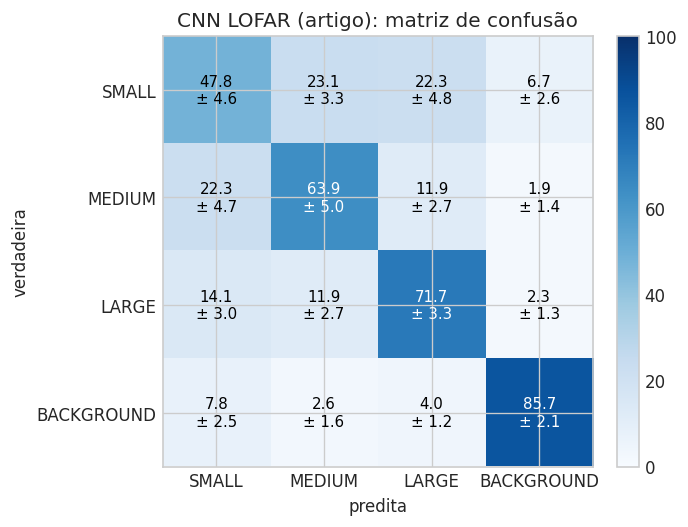

In [3]:
CMf = []
for k, d in D.groupby('fold'):
    cm = pd.crosstab(d.Classe, d.Predita, normalize='index').reindex(index=R.CLASSES, columns=R.CLASSES).fillna(0) * 100
    CMf.append(cm.values)
CMf = np.array(CMf)
CM = pd.DataFrame(CMf.mean(0), index=R.CLASSES, columns=R.CLASSES)
CMs = pd.DataFrame(CMf.std(0), index=R.CLASSES, columns=R.CLASSES)
print('Matriz de confusão (% por linha; média ± desvio dos 10 folds):')
display(CM.round(1).astype(str) + ' ± ' + CMs.round(1).astype(str))

fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(CM.values, cmap='Blues', vmin=0, vmax=100)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f'{CM.values[i, j]:.1f}\n± {CMs.values[i, j]:.1f}', ha='center', va='center',
                color='white' if CM.values[i, j] > 55 else 'black', fontsize=9)
ax.set_xticks(range(4), R.CLASSES); ax.set_yticks(range(4), R.CLASSES)
ax.set_xlabel('predita'); ax.set_ylabel('verdadeira'); ax.set_title('CNN LOFAR (artigo): matriz de confusão')
plt.colorbar(im, ax=ax, fraction=0.046); plt.tight_layout(); plt.show()

**Leitura.**
- **SMALL:** 47,8 ± 4,6% de acerto; vai para MEDIUM 23,1% e LARGE 22,3% quase na mesma proporção.
- **MEDIUM:** 63,9 ± 5,0%; a confusão principal é com SMALL (22,3%), depois LARGE (11,9%).
- **LARGE** 71,7% e **BACKGROUND** 85,7%. Os três tamanhos de navio se confundem entre si; o ruído de fundo é separado com mais facilidade.

## 3. Erros em SMALL

Cada gravação é teste em ~5 folds (uma vez por repetição do 5×2cv). "Sempre erra" = a CNN errou em todos eles.

SMALL — consistência da CNN em cada gravação (nos ~5 folds em que ela é teste):


,gravações
CNN,
sempre acerta,122
às vezes,208
sempre erra,146


SMALL — para onde vão os erros (%):


,%
Predita,
SMALL,0.0
MEDIUM,44.3
LARGE,42.7
BACKGROUND,12.9


SMALL — acerto com o navio visto × não visto no treino do fold:


...

,nome,tipo,comprimento,gravações,erro_cnn
Ship ID,,,,,
603,TS METIDO,Tug,27.0,3,1.0
459,PILOT BOAT V,Fishing Vessel,8.0,2,1.0
626,VO NICACIO,Fishing Vessel,20.0,2,1.0
159,ECO GLADIATOR,Tug,34.0,1,1.0
309,M ILHAVO,Tug,19.0,1,1.0
340,MARCOS FELIPE,Fishing Vessel,22.0,1,1.0
342,MARFORT 22,Tug,19.0,1,1.0
448,PILOT 01,Pilot Vessel,11.0,1,1.0
460,PILOTS IV,Fishing Vessel,19.0,1,1.0


SMALL por tipo de navio (≥ 5 gravações):


,gravações,navios,acerto_cnn
DETAILED TYPE,,,
Pilot Vessel,321,15,49.5
Tug,87,34,38.5
Fishing Vessel,33,22,40.7
Offshore Supply Ship,8,3,50.0
High-Speed Craft,8,2,72.7
Pleasure Craft,7,4,39.3
Mooring Vessel,5,2,53.3


SMALL — espectro × erro da CNN:


,sempre acerta (mediana),sempre erra (mediana),ρ Spearman com o erro da CNN,p
energia 0-200 Hz (%),45.20,64.87,0.20,0.00
energia 1000-5000 Hz (%),15.64,10.12,-0.21,0.00
centroide (Hz),1634.21,1082.56,-0.20,0.00
planura 0–5 kHz,0.28,0.17,-0.21,0.00
ganho no CPA (dB),2.91,3.29,0.05,0.26


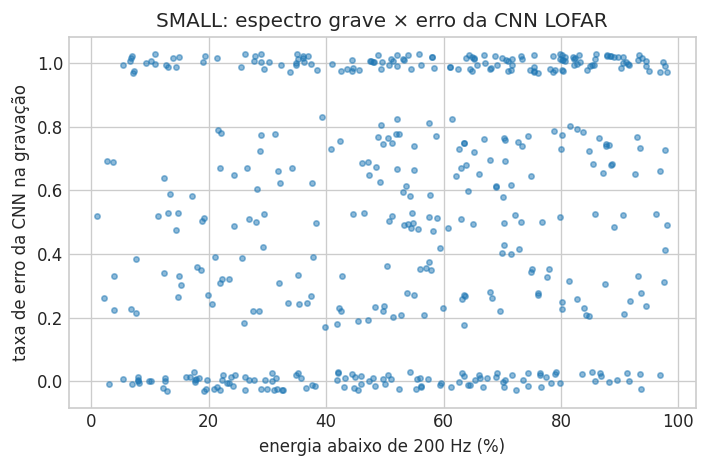

In [4]:
def estudo_classe(c):
    g = G[G.Target == c]
    dd = D[D.Target == c]
    out = {}
    out['consistência'] = g.CNN.value_counts().reindex(['sempre acerta', 'às vezes', 'sempre erra']).fillna(0).astype(int)
    out['destino'] = dd[~dd.acertou].Predita.value_counts(normalize=True).mul(100).reindex(R.CLASSES).fillna(0)
    nv = dd.groupby('navio no treino').acertou.agg(['mean', 'size']); nv['mean'] *= 100
    out['navio'] = nv.rename(columns={'mean': 'acerto (%)', 'size': 'predições'})
    out['nb32'] = g.groupby('grupo NB32').agg(gravações=('erro_cnn', 'size'), acerto_cnn=('erro_cnn', lambda s: 100 * (1 - s.mean())),
                                             erram_de_16=('erram (de 16)', 'mean')).reindex(['fácil', 'meio', 'núcleo'])
    nav = g.groupby('Ship ID').agg(nome=('Name', 'first'), tipo=('DETAILED TYPE', 'first'), comprimento=('Length', 'first'),
                                   gravações=('erro_cnn', 'size'), erro_cnn=('erro_cnn', 'mean'))
    out['navios'] = nav
    return out

ES = estudo_classe(SMALL)
print('SMALL — consistência da CNN em cada gravação (nos ~5 folds em que ela é teste):'); display(ES['consistência'].to_frame('gravações'))
print('SMALL — para onde vão os erros (%):'); display(ES['destino'].round(1).to_frame('%'))
print('SMALL — acerto com o navio visto × não visto no treino do fold:'); display(ES['navio'].round(1))
print('SMALL — acerto da CNN LOFAR nos grupos do Notebook 32 (16 modelos):'); display(ES['nb32'].round(1))
nvS = ES['navios']
print(f"SMALL — navios: {len(nvS)}; navios com erro médio ≥ 50%: {(nvS.erro_cnn >= 0.5).sum()}")
display(nvS.sort_values(['erro_cnn', 'gravações'], ascending=False).head(12).round(2))
print('SMALL por tipo de navio (≥ 5 gravações):')
TPs = G[G.Target == SMALL].groupby('DETAILED TYPE').agg(gravações=('erro_cnn', 'size'), navios=('Ship ID', 'nunique'),
                                                      acerto_cnn=('erro_cnn', lambda s: 100 * (1 - s.mean())))
display(TPs[TPs.gravações >= 5].sort_values('gravações', ascending=False).round(1))

if FEAT is not None:
    gS = G[G.Target == SMALL]
    FCOLS = ['energia 0-200 Hz (%)', 'energia 1000-5000 Hz (%)', 'centroide (Hz)', 'planura 0–5 kHz', 'ganho no CPA (dB)']
    AS = pd.DataFrame({c: {'sempre acerta (mediana)': gS.loc[gS.CNN == 'sempre acerta', c].median(),
                           'sempre erra (mediana)': gS.loc[gS.CNN == 'sempre erra', c].median(),
                           'ρ Spearman com o erro da CNN': spearmanr(gS[c], gS.erro_cnn, nan_policy='omit')[0],
                           'p': spearmanr(gS[c], gS.erro_cnn, nan_policy='omit')[1]} for c in FCOLS}).T
    print('SMALL — espectro × erro da CNN:'); display(AS.round(3))
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.scatter(gS['energia 0-200 Hz (%)'], gS.erro_cnn + np.random.default_rng(0).uniform(-0.03, 0.03, len(gS)), s=10, alpha=0.5)
    ax.set_xlabel('energia abaixo de 200 Hz (%)'); ax.set_ylabel('taxa de erro da CNN na gravação')
    ax.set_title('SMALL: espectro grave × erro da CNN LOFAR'); plt.tight_layout(); plt.show()

**Leitura.**
- **Consistência:** das 476 gravações SMALL, a CNN sempre acerta 122, sempre erra 146 e oscila em 208 (44%). Como nos outros modelos (NB32), boa parte do SMALL está perto da fronteira de decisão.
- **Destino dos erros:** MEDIUM 44,3%, LARGE 42,7%, BACKGROUND 12,9%.
- **Navio no treino:** acerto 49,3% com o navio visto contra 38,4% sem (+10,9 pontos).
- **Grupos do NB32:** acerto da CNN fácil 80,2%, meio 47,7%, núcleo 1,0%. A CNN segue o mesmo padrão dos 16 modelos: acerta as fáceis, oscila no meio e quase não acerta o núcleo.
- **Espectro:** Nas gravações SMALL que a CNN **sempre erra**, a energia abaixo de 200 Hz tem mediana de 65%, contra 45% nas que ela sempre acerta (ρ de Spearman com o erro = 0,20, p < 0,001). O espectro grave, que explicava os erros dos outros modelos (NB32), também explica os da CNN LOFAR.

## 4. Erros em MEDIUM

MEDIUM são navios de 50 a 100 m. Os erros para SMALL se concentram perto de 50 m? Para LARGE, perto de 100 m?

In [5]:
EM = estudo_classe(MEDIUM)
print('MEDIUM — consistência:'); display(EM['consistência'].to_frame('gravações'))
print('MEDIUM — para onde vão os erros (%):'); display(EM['destino'].round(1).to_frame('%'))
print('MEDIUM — navio visto × não visto:'); display(EM['navio'].round(1))
print('MEDIUM — grupos do Notebook 32:'); display(EM['nb32'].round(1))

dM = D[D.Target == MEDIUM].join(meta[['Length', 'DETAILED TYPE']], on='File')
bins = [50, 60, 70, 80, 90, 100]
LEN = dM.groupby(pd.cut(dM.Length, bins, right=False), observed=False).agg(predições=('acertou', 'size'), acerto=('acertou', 'mean'),
                                                          vai_SMALL=('Prediction', lambda s: (s == SMALL).mean()),
                                                          vai_LARGE=('Prediction', lambda s: (s == LARGE).mean()))
LEN[['acerto', 'vai_SMALL', 'vai_LARGE']] *= 100
print('MEDIUM por comprimento (m): acerto e destino dos erros (%):'); display(LEN.round(1))
TPm = dM.groupby('DETAILED TYPE').agg(predições=('acertou', 'size'), navios=('File', lambda s: meta.loc[s, 'Ship ID'].nunique()),
                                      acerto=('acertou', lambda s: 100 * s.mean()))
print('MEDIUM por tipo de navio (≥ 20 predições):'); display(TPm[TPm.predições >= 20].sort_values('predições', ascending=False).round(1))
nvM = EM['navios']
print(f"MEDIUM — navios: {len(nvM)}; navios com erro médio ≥ 50%: {(nvM.erro_cnn >= 0.5).sum()}")
display(nvM.sort_values(['erro_cnn', 'gravações'], ascending=False).head(12).round(2))
rho_len = spearmanr(dM.Length, dM.Prediction == SMALL)[0]

MEDIUM — consistência:


,gravações
CNN,
sempre acerta,193
às vezes,129
sempre erra,75


MEDIUM — para onde vão os erros (%):


,%
Predita,
SMALL,61.9
MEDIUM,0.0
LARGE,32.9
BACKGROUND,5.2


MEDIUM — navio visto × não visto:


...

,predições,acerto,vai_SMALL,vai_LARGE
Length,,,,
"[50, 60)",26,26.9,42.3,26.9
"[60, 70)",147,51.0,27.2,20.4
"[70, 80)",777,76.4,16.0,6.4
"[80, 90)",450,47.6,32.0,16.9
"[90, 100)",90,68.9,15.6,15.6


MEDIUM por tipo de navio (≥ 20 predições):


,predições,navios,acerto
DETAILED TYPE,,,
Motor Hopper,544,3,88.1
Offshore Supply Ship,524,46,53.1
Supply Vessel,136,7,45.6
Anchor Handling Vessel,110,6,42.7
Tug/Supply Vessel,86,5,61.6
Multi Purpose Offshore Vessel,47,6,53.2


MEDIUM — navios: 82; navios com erro médio ≥ 50%: 43


,nome,tipo,comprimento,gravações,erro_cnn
Ship ID,,,,,
152,DON IGNACIO,Offshore Supply Ship,62.0,2,1.0
507,SAVEIROS FRAGATA,Offshore Supply Ship,72.0,2,1.0
107,CBO IPANEMA,Offshore Supply Ship,89.0,1,1.0
13,ALCATRAZ,Offshore Supply Ship,90.0,1,1.0
241,HELEN,Livestock Carrier,80.0,1,1.0
242,HELLAS TUNA,Fishing Vessel,83.0,1,1.0
251,HOS RUNNING BUCK,Offshore Supply Ship,84.0,1,1.0
277,JONES TIDE,Offshore Supply Ship,84.0,1,1.0
316,MAERSK LEADER,Offshore Supply Ship,90.0,1,1.0


**Leitura.**
- **Consistência:** sempre acerta 193, sempre erra 75, oscila 129 de 397 gravações.
- **Destino dos erros:** SMALL 61,9%, LARGE 32,9%, BACKGROUND 5,2%.
- **Comprimento:** na faixa de [50, 60) m, 42,3% das predições vão para SMALL; na faixa de [90, 100) m, 15,6% vão para LARGE (veja a tabela por faixa). A relação com o comprimento não é monotônica (a faixa de 80–90 m erra mais que a de 70–80 m, dominada por Motor Hoppers bem reconhecidos): o erro não se explica só pela proximidade dos limiares.
- **Navio no treino:** acerto 67,6% com o navio visto contra 42,1% sem (+25,5 pontos).
- **Tipo:** o tipo mais frequente é Motor Hopper (acerto 88,1%). Como no NB32, o tipo de navio pesa: tipos com muitas gravações de poucos navios são mais fáceis.

## 5. A CNN estava insegura quando errou?

Concordância das janelas (fração que vota na classe vencedora) e margem (diferença entre as duas maiores probabilidades médias), por classe verdadeira.

In [6]:
rows = []
for c in (SMALL, MEDIUM, LARGE, BG):
    g = D[D.Target == c]
    rows.append({'classe': CLS[c], 'erro (%)': 100 * (1 - g.acertou.mean()),
                 'concordância: acerto': g[g.acertou].agreement.median(), 'concordância: erro': g[~g.acertou].agreement.median(),
                 'AUC concordância': roc_auc_score(g.acertou, g.agreement),
                 'margem: acerto': g[g.acertou].margem.median(), 'margem: erro': g[~g.acertou].margem.median(),
                 'AUC margem': roc_auc_score(g.acertou, g.margem)})
CONF = pd.DataFrame(rows).set_index('classe')
print('Confiança da CNN LOFAR quando acerta × quando erra (AUC = 0,5: não separa):'); display(CONF.round(3))

Confiança da CNN LOFAR quando acerta × quando erra (AUC = 0,5: não separa):


,erro (%),concordância: acerto,concordância: erro,AUC concordância,margem: acerto,margem: erro,AUC margem
classe,,,,,,,
SMALL,52.19,0.77,0.77,0.52,0.27,0.24,0.54
MEDIUM,36.11,0.92,0.77,0.66,0.51,0.21,0.70
LARGE,28.27,1.00,0.69,0.74,0.60,0.20,0.77
BACKGROUND,14.29,1.00,0.77,0.82,0.98,0.26,0.93


**Leitura.**
- AUC da margem: SMALL 0,54, MEDIUM 0,70, LARGE 0,77, BACKGROUND 0,93; da concordância: SMALL 0,52, MEDIUM 0,66, LARGE 0,74, BACKGROUND 0,82.
- **SMALL:** como o MEL no NB32, a CNN LOFAR erra com a mesma convicção com que acerta (AUC ≈ 0,5): a confiança não serve para identificar esses erros.
- **MEDIUM, LARGE e BACKGROUND:** a confiança separa cada vez melhor (AUC da margem de 0,70 a 0,93). O SMALL é a única classe em que os erros são "convictos".

## 6. A CNN LOFAR erra as mesmas gravações que os outros modelos?

In [7]:
def q_yule(a, b):
    n11, n00, n10, n01 = (a & b).sum(), (~a & ~b).sum(), (a & ~b).sum(), (~a & b).sum()
    return (n11 * n00 - n10 * n01) / (n11 * n00 + n10 * n01)

rows = []
for nome, (exp, _) in OUTROS.items():
    qs, qss, resg = [], [], []
    for k in range(10):
        a = FP[k][['File', 'Target', 'Prediction']].merge(R.file_predictions(exp)[k][['File', 'Prediction']], on='File', suffixes=('_cnn', '_o'))
        ec, eo = a.Prediction_cnn != a.Target, a.Prediction_o != a.Target
        qs.append(q_yule(ec.values, eo.values))
        m = a.Target == SMALL
        qss.append(q_yule(ec[m].values, eo[m].values))
        resg.append(100 * (~ec[m] & eo[m]).sum() / max(eo[m].sum(), 1))
    rows.append({'modelo': nome, 'Q dos erros (todas)': np.nanmean(qs), 'Q dos erros (SMALL)': np.nanmean(qss),
                 'erros SMALL do modelo que a CNN acerta (%)': np.mean(resg)})
QO = pd.DataFrame(rows).set_index('modelo')
print('CNN LOFAR × outros modelos: erram as mesmas gravações?'); display(QO.round(2))

gS = G[G.Target == SMALL]
RESG = gS.groupby('grupo NB32').agg(gravações=('erro_cnn', 'size'),
                                    CNN_sempre_acerta=('CNN', lambda s: (s == 'sempre acerta').sum()),
                                    acerto_medio_cnn=('erro_cnn', lambda s: 100 * (1 - s.mean()))).reindex(['fácil', 'meio', 'núcleo'])
print('SMALL: a CNN LOFAR resgata gravações que os 16 modelos erram?'); display(RESG.round(1))
NUC_OK = gS[(gS['grupo NB32'] == 'núcleo') & (gS.erro_cnn < 0.5)]
print(f'Gravações do núcleo do NB32 que a CNN acerta na maioria dos folds: {len(NUC_OK)}')
if len(NUC_OK):
    display(NUC_OK[['Arquivo', 'Name', 'DETAILED TYPE', 'Length', 'erram (de 16)', 'erro_cnn']].round(2))

CNN LOFAR × outros modelos: erram as mesmas gravações?


,Q dos erros (todas),Q dos erros (SMALL),erros SMALL do modelo que a CNN acerta (%)
modelo,,,
MLP LOFAR,0.92,0.81,24.42
MLP MEL,0.82,0.64,31.94
RF LOFAR,0.84,0.61,31.43
RF MEL,0.70,0.49,32.73
CNN MEL,0.88,0.77,28.49
SVM MEL,0.81,0.63,29.62
SVM LOFAR,0.89,0.75,30.62
BiGRU MEL,0.78,0.56,33.77
BiGRU LOFAR,0.80,0.60,29.16


SMALL: a CNN LOFAR resgata gravações que os 16 modelos erram?


,gravações,CNN_sempre_acerta,acerto_medio_cnn
grupo NB32,,,
fácil,35,21,80.2
meio,415,101,47.7
núcleo,26,0,1.0


Gravações do núcleo do NB32 que a CNN acerta na maioria dos folds: 0


**Leitura.**
- Q de Yule dos erros (todas as classes) com os outros modelos: MLP LOFAR 0,92, MLP MEL 0,82, RF LOFAR 0,84, RF MEL 0,70, CNN MEL 0,88, SVM MEL 0,81, SVM LOFAR 0,89, BiGRU MEL 0,78, BiGRU LOFAR 0,80. Os erros da CNN LOFAR são fortemente associados aos de todos os outros modelos; o mais associado é o MLP LOFAR (0,92).
- Dos erros SMALL de cada modelo, a CNN acerta de 24% a 34%.
- **Núcleo do NB32:** 0 das 26 gravações que ≥ 15 de 16 modelos erram são acertadas pela CNN na maioria dos folds. A CNN LOFAR não muda o diagnóstico do NB32.

## 7. Conclusões

1. **A CNN LOFAR do artigo foi reproduzida:** SP 66,49 ± 1,28, contra 66,05 ± 1,90 no artigo. A configuração importa: a versão inicial (sem sobreposição, paciência 16) dava 62,8 no fold 0, contra 68,5 da versão do artigo.
2. **Contra os MLPs (os modelos mais próximos dos do artigo), a Tabela 8 se repete:** a CNN LOFAR não é significativamente melhor que eles.
3. **Ter o navio no treino pesa:** +10,9 pontos de acerto no SMALL e +25,5 no MEDIUM (o split por gravação do artigo põe o mesmo navio em treino e teste).
4. **O SMALL continua sendo o problema** (47,8% de recall), com erros divididos entre MEDIUM e LARGE; o **MEDIUM** se confunde sobretudo com SMALL.
5. **Os erros da CNN seguem o mesmo padrão dos outros modelos:** gravações na fronteira que oscilam entre folds, erros convictos, espectro grave nas gravações SMALL que ela sempre erra, e o núcleo do NB32 continua sem solução. O melhor modelo do artigo não tem acesso a uma informação que os outros não tenham.

**Limites:**
- Split por gravação (`ID`), como no artigo; o NB29 mostrou que ele infla os resultados (navio no treino e no teste).
- O modelo salvo é o da última época, não o de menor perda de validação (comportamento de `trainer.py` preservado para reproduzir o artigo).
- O texto do artigo diz padding 1; o código usado pelos autores dá padding 2 (mantido o do código).